# Codveda Data Analytics Internship - Level 3 (Advanced)
**Task 1:** Predictive Modeling (Classification)

Dataset: scikit-learn's Breast Cancer Wisconsin dataset (predict malignant vs benign).
Same pipeline applies to a churn dataset: change `load_data()`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

sns.set_theme(style="whitegrid")
os.makedirs("plots", exist_ok=True)

def load_data():
    d = load_breast_cancer(as_frame=True)
    X, y = d.data, d.target          # target: 0 = malignant, 1 = benign
    return X, y, d.target_names

X, y, names = load_data()
print(X.shape, "| class balance:", y.value_counts(normalize=True).round(3).to_dict())

(569, 30) | class balance: {1: 0.627, 0: 0.373}


## 1. Preprocessing
All features are numeric (for datasets with categorical columns use `pd.get_dummies`).
Scaling is done inside a Pipeline so it is fit only on training data (no leakage).

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

models = {
    "Logistic Regression": Pipeline([("scale", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))]),
    "Decision Tree": Pipeline([("scale", StandardScaler()), ("clf", DecisionTreeClassifier(random_state=42))]),
    "Random Forest": Pipeline([("scale", StandardScaler()), ("clf", RandomForestClassifier(random_state=42))]),
}

## 2. Train and evaluate baseline models

In [3]:
def evaluate(model, name):
    p = model.predict(X_test)
    return {"Model": name, "Accuracy": accuracy_score(y_test, p), "Precision": precision_score(y_test, p),
            "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)}

rows = []
for n, m in models.items():
    m.fit(X_train, y_train)
    rows.append(evaluate(m, n))
baseline = pd.DataFrame(rows).set_index("Model").round(3)
print(baseline)

                     Accuracy  Precision  Recall     F1
Model                                                  
Logistic Regression     0.982      0.986   0.986  0.986
Decision Tree           0.912      0.956   0.903  0.929
Random Forest           0.956      0.959   0.972  0.966


## 3. Hyperparameter tuning with grid search (5-fold CV, optimizing F1)

In [4]:
grids = {
    "Logistic Regression": {"clf__C": [0.01, 0.1, 1, 10, 100]},
    "Decision Tree": {"clf__max_depth": [2, 3, 5, 8, None], "clf__min_samples_split": [2, 5, 10]},
    "Random Forest": {"clf__n_estimators": [100, 200, 300], "clf__max_depth": [None, 5, 10], "clf__min_samples_split": [2, 5]},
}
tuned, rows = {}, []
for n, m in models.items():
    gs = GridSearchCV(m, grids[n], cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)
    tuned[n] = gs.best_estimator_
    print(f"{n}: best params = {gs.best_params_}  (CV F1 = {gs.best_score_:.3f})")
    rows.append(evaluate(gs.best_estimator_, n))
tuned_df = pd.DataFrame(rows).set_index("Model").round(3)
print("\nTuned models on test set:\n", tuned_df)

Logistic Regression: best params = {'clf__C': 0.1}  (CV F1 = 0.985)
Decision Tree: best params = {'clf__max_depth': 5, 'clf__min_samples_split': 5}  (CV F1 = 0.952)
Random Forest: best params = {'clf__max_depth': None, 'clf__min_samples_split': 2, 'clf__n_estimators': 300}  (CV F1 = 0.967)

Tuned models on test set:
                      Accuracy  Precision  Recall     F1
Model                                                  
Logistic Regression     0.974      0.973   0.986  0.979
Decision Tree           0.921      0.957   0.917  0.936
Random Forest           0.947      0.958   0.958  0.958


## 4. Compare models and inspect the best one

Best model: Logistic Regression
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



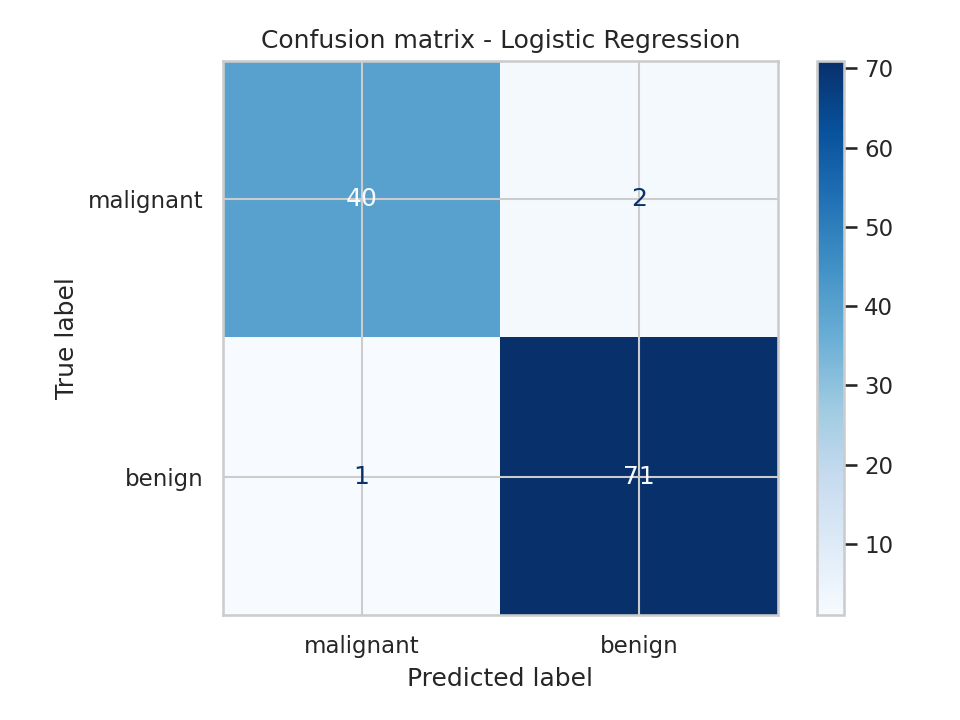

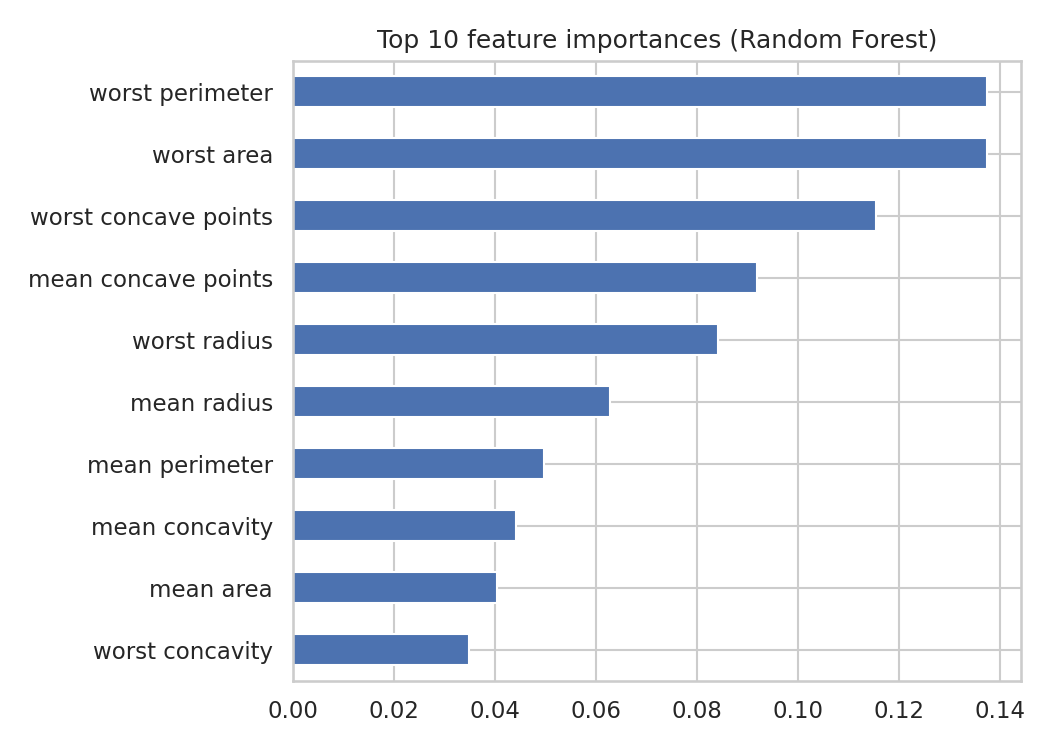

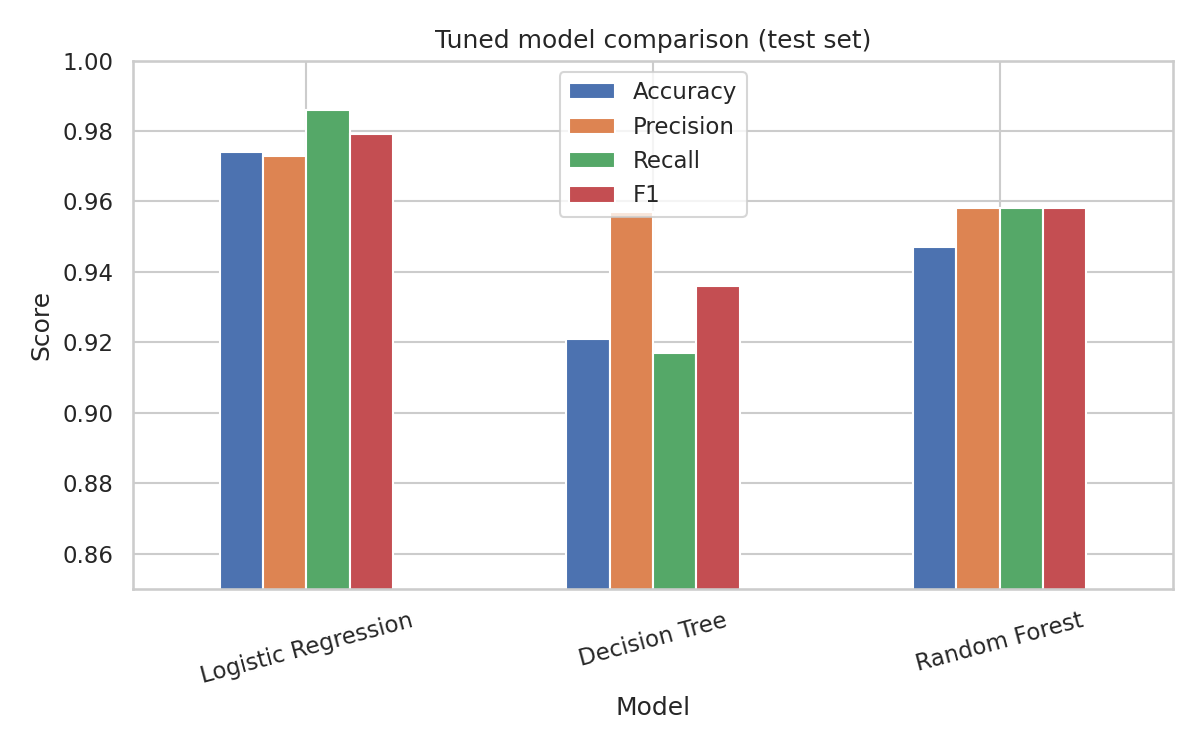

In [5]:
comp = pd.concat({"Baseline": baseline, "Tuned": tuned_df}, axis=1)
comp.to_csv("model_comparison.csv")

ax = tuned_df.plot(kind="bar", figsize=(8, 5), rot=15, ylim=(0.85, 1.0))
ax.set_title("Tuned model comparison (test set)"); ax.set_ylabel("Score")
plt.tight_layout(); plt.savefig("plots/model_comparison.png", dpi=150); plt.close()

best_name = tuned_df["F1"].idxmax()
best = tuned[best_name]
print("Best model:", best_name)
print(classification_report(y_test, best.predict(X_test), target_names=names))

ConfusionMatrixDisplay(confusion_matrix(y_test, best.predict(X_test)), display_labels=names).plot(cmap="Blues")
plt.title(f"Confusion matrix - {best_name}")
plt.tight_layout(); plt.savefig("plots/confusion_matrix.png", dpi=150); plt.close()

rf = tuned["Random Forest"].named_steps["clf"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot(kind="barh", figsize=(7, 5), title="Top 10 feature importances (Random Forest)")
plt.tight_layout(); plt.savefig("plots/feature_importance.png", dpi=150); plt.close()